# OS2 — Reconnaissance faciale et stratégies d'adaptation

**Objectif :** détecter l'émotion faciale (FER), la mapper vers DAiSEE, puis appliquer les règles de stratégie pédagogique (types A, B, C, D).

**Prérequis :**
- `data/scenarios_50.csv` (OS1)
- `data/sample_face.jpg` — photo de visage pour la démo
- `backend/adaptation.py`

**Fichier produit :** `data/scenarios_avec_strategies.csv`

In [13]:
from pathlib import Path

def trouver_image_test():
    """Cherche une image de visage dans data/ (fichier, pas dossier)."""
    candidats = (
        
        "images.jfif",
    )
    data_dir = (Path("..") / "data").resolve()
    for name in candidats:
        p = data_dir / name
        if p.is_file():
            return p
    raise FileNotFoundError(
        f"Aucune image trouvée dans {data_dir}. "
        "Placez une photo de visage (ex. sample_face.jpg) dans data/."
    )

IMAGE_TEST = trouver_image_test()
print(f"Image de test : {IMAGE_TEST}")

Image de test : C:\Users\Lenovo\EmoLearn\data\images.jfif


In [10]:
from transformers import pipeline
from PIL import Image

print("Chargement du modèle FER...")
print("(première fois = téléchargement 2-3 minutes)\n")
# Charger le modèle pré-entraîné

detecteur = pipeline(
    "image-classification",
    model="dima806/facial_emotions_image_detection",
    device=-1  # CPU
)

print("Modèle chargé avec succès ✅")

Chargement du modèle FER...
(première fois = téléchargement 2-3 minutes)



Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Modèle chargé avec succès ✅


In [14]:
# Charger et analyser l'image
image = Image.open(IMAGE_TEST)

print("Analyse en cours...")
result = detecteur(image)

# Afficher les résultats
print("\n=== RÉSULTATS FER ===\n")
print(f"Émotion dominante : {result[0]['label']}")
print(f"\nToutes les émotions détectées :")
for emotion in result:
    print(f"  {emotion['label']} : {emotion['score']*100:.2f}%")

Analyse en cours...

=== RÉSULTATS FER ===

Émotion dominante : happy

Toutes les émotions détectées :
  happy : 39.75%
  angry : 26.27%
  surprise : 10.45%
  fear : 9.67%
  neutral : 7.76%


In [15]:
# Mapper vers état DAiSEE
def mapper_emotion_daisee(emotion_fer):
    mapping = {
        'happy'    : {'etat': 'Engagement',  'niveau': 3},
        'surprise' : {'etat': 'Confusion',   'niveau': 2},
        'neutral'  : {'etat': 'Boredom',     'niveau': 1},
        'sad'      : {'etat': 'Boredom',     'niveau': 2},
        'angry'    : {'etat': 'Frustration', 'niveau': 3},
        'fear'     : {'etat': 'Confusion',   'niveau': 3},
        'disgust'  : {'etat': 'Frustration', 'niveau': 2}
    }
    return mapping.get(emotion_fer.lower(), {'etat': 'Engagement', 'niveau': 1})

# Tester le mapping
emotion_dominante = result[0]['label']
etat = mapper_emotion_daisee(emotion_dominante)

print("=== MAPPING ÉMOTIONS → ÉTATS DAISEE ===\n")
print(f"Émotion FER détectée : {emotion_dominante}")
print(f"État DAiSEE          : {etat['etat']}")
print(f"Niveau               : {etat['niveau']}")

=== MAPPING ÉMOTIONS → ÉTATS DAISEE ===

Émotion FER détectée : happy
État DAiSEE          : Engagement
Niveau               : 3


In [16]:
# ============================================
# PIPELINE COMPLET FER + STRATÉGIE
# ============================================

import sys
sys.path.append('../backend')
from adaptation import selectionner_strategie, get_description_strategie

def analyser_image_complete(image_path):
    print(f"=== ANALYSE COMPLÈTE ===\n")

    # Étape 1 — Détecter l'émotion
    image = Image.open(image_path)
    result = detecteur(image)
    emotion_fer = result[0]['label']
    confiance = result[0]['score'] * 100
    print(f"1. Émotion FER détectée : {emotion_fer} ({confiance:.1f}%)")

    # Étape 2 — Mapper vers état DAiSEE
    etat_daisee = mapper_emotion_daisee(emotion_fer)
    print(f"2. État DAiSEE          : {etat_daisee['etat']} (niveau {etat_daisee['niveau']})")

    # Étape 3 — Sélectionner la stratégie
    boredom     = etat_daisee['niveau'] if etat_daisee['etat'] == 'Boredom'     else 0
    confusion   = etat_daisee['niveau'] if etat_daisee['etat'] == 'Confusion'   else 0
    engagement  = etat_daisee['niveau'] if etat_daisee['etat'] == 'Engagement'  else 1
    frustration = etat_daisee['niveau'] if etat_daisee['etat'] == 'Frustration' else 0

    emotion, niveau, strategie, type_c = selectionner_strategie(
        boredom, confusion, engagement, frustration
    )
    description = get_description_strategie(type_c)

    print(f"3. Stratégie choisie    : {strategie}")
    print(f"4. Type de contenu      : {type_c} — {description}")

    return {
        'emotion_fer' : emotion_fer,
        'etat_daisee' : etat_daisee['etat'],
        'niveau'      : etat_daisee['niveau'],
        'strategie'   : strategie,
        'type_contenu': type_c
    }

# Tester
resultat = analyser_image_complete(IMAGE_TEST)

=== ANALYSE COMPLÈTE ===

1. Émotion FER détectée : happy (39.8%)
2. État DAiSEE          : Engagement (niveau 3)
3. Stratégie choisie    : Renforcement positif
4. Type de contenu      : D — Encouragement motivationnel — Support émotionnel


In [17]:
# ============================================
# ÉVALUATION SUR 50 SCÉNARIOS
# ============================================

import pandas as pd

# Charger les 50 scénarios
scenarios = pd.read_csv('../data/scenarios_50.csv')
scenarios.columns = scenarios.columns.str.strip()

print("=== ÉVALUATION MAPPING SUR 50 SCÉNARIOS ===\n")

resultats = []
for _, row in scenarios.iterrows():
    emotion, niveau, strategie, type_c = selectionner_strategie(
        row['Boredom'],
        row['Confusion'],
        row['Engagement'],
        row['Frustration']
    )
    resultats.append({
        'ClipID'      : row['ClipID'],
        'pattern'     : row['pattern'],
        'emotion'     : emotion,
        'niveau'      : niveau,
        'strategie'   : strategie,
        'type_contenu': type_c
    })

df_resultats = pd.DataFrame(resultats)

print("Répartition des types de contenu appliqués :")
print(df_resultats['type_contenu'].value_counts())
print(f"\nTotal scénarios traités : {len(df_resultats)}")

# Sauvegarder
df_resultats.to_csv('../data/scenarios_avec_strategies.csv', index=False)
print("\nRésultats sauvegardés !")

=== ÉVALUATION MAPPING SUR 50 SCÉNARIOS ===

Répartition des types de contenu appliqués :
type_contenu
D+A    16
C      11
A       8
B       7
D       6
A+D     2
Name: count, dtype: int64

Total scénarios traités : 50

Résultats sauvegardés !


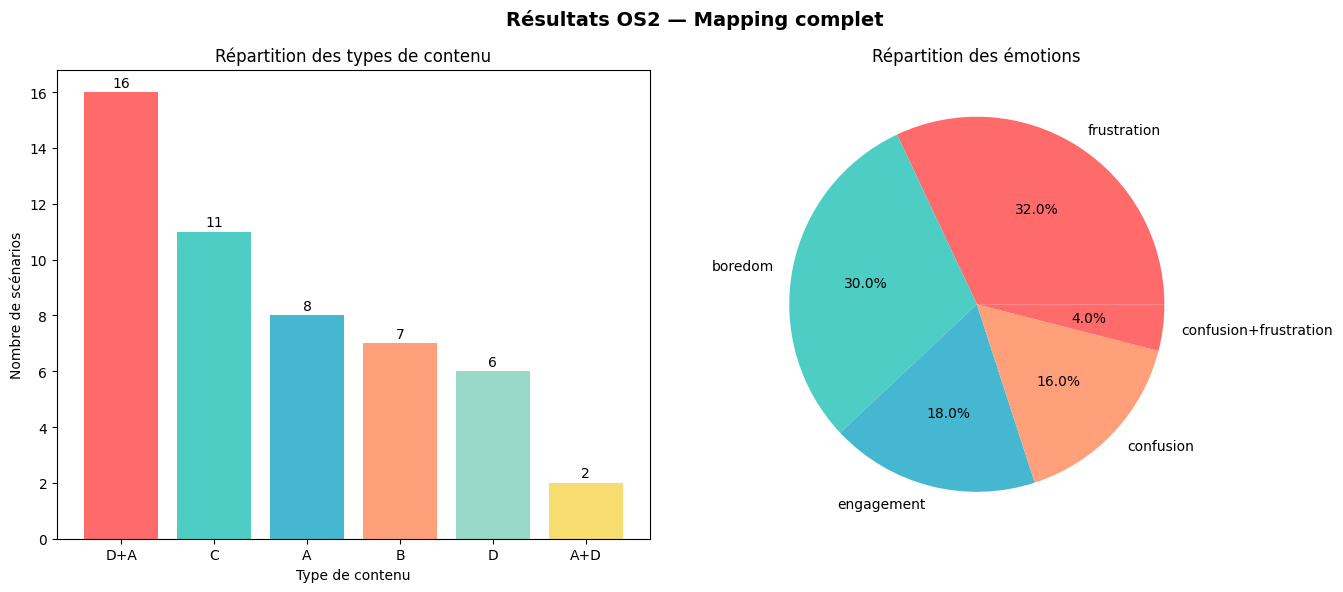

              RÉSUMÉ FINAL OS2 — COMPLET

✅ Modèle FER             : HuggingFace (7 émotions détectées)
✅ Mapping DAiSEE         : 7 émotions → 4 états + 6 combinaisons
✅ Types de contenu       : 6 types (A, B, C, D, A+D, D+A)
✅ Règles de déclenchement: 6 types de stratégie (A, B, C, D, A+D, D+A)
✅ Scénarios testés       : 50/50

📊 Répartition des stratégies appliquées :
   Type D+A : 16 scénarios ( 32.0%)
   Type C : 11 scénarios ( 22.0%)
   Type A :  8 scénarios ( 16.0%)
   Type B :  7 scénarios ( 14.0%)
   Type D :  6 scénarios ( 12.0%)
   Type A+D :  2 scénarios (  4.0%)

📁 Fichiers sauvegardés :
   - data/scenarios_avec_strategies.csv
   - data/os2_resultats.png

✅ OS2 TERMINÉ AVEC SUCCÈS !


In [19]:
# ============================================
# OS2 — RÉSUMÉ FINAL COMPLET
# ============================================

import matplotlib.pyplot as plt

# 1. Graphique de répartition
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Résultats OS2 — Mapping complet', fontsize=14, fontweight='bold')

# Graphique 1
type_counts = df_resultats['type_contenu'].value_counts()
axes[0].bar(type_counts.index, type_counts.values, color=['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A', '#98D8C8', '#F7DC6F'])
axes[0].set_title('Répartition des types de contenu', fontsize=12)
axes[0].set_xlabel('Type de contenu')
axes[0].set_ylabel('Nombre de scénarios')
for i, (idx, val) in enumerate(type_counts.items()):
    axes[0].text(i, val + 0.2, str(val), ha='center', fontsize=10)

# Graphique 2
emotion_counts = df_resultats['emotion'].value_counts()
axes[1].pie(emotion_counts.values, labels=emotion_counts.index, autopct='%1.1f%%',
            colors=['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A'])
axes[1].set_title('Répartition des émotions', fontsize=12)

plt.tight_layout()
plt.savefig('../data/os2_resultats.png', dpi=150)
plt.show()

# 2. Résumé
print("=" * 60)
print("              RÉSUMÉ FINAL OS2 — COMPLET")
print("=" * 60)
print(f"\n✅ Modèle FER             : HuggingFace (7 émotions détectées)")
print(f"✅ Mapping DAiSEE         : 7 émotions → 4 états + 6 combinaisons")
print(f"✅ Types de contenu       : 6 types (A, B, C, D, A+D, D+A)")
print(f"✅ Règles de déclenchement: 6 types de stratégie (A, B, C, D, A+D, D+A)")
print(f"✅ Scénarios testés       : 50/50")
print(f"\n📊 Répartition des stratégies appliquées :")
for idx, val in type_counts.items():
    pct = (val/50)*100
    print(f"   Type {idx} : {val:2d} scénarios ({pct:5.1f}%)")
print(f"\n📁 Fichiers sauvegardés :")
print(f"   - data/scenarios_avec_strategies.csv")
print(f"   - data/os2_resultats.png")
print(f"\n✅ OS2 TERMINÉ AVEC SUCCÈS !")
print("=" * 60)